<a href="https://colab.research.google.com/github/josephenik2-design/Applied-AI-Sequence-Models/blob/main/Auditing%20Very%20Small%2C%20Imbalanced%20Fraud%20Datasets%20Before%20Deployment%3A%20A%20Risk-Based%20Protocol%20and%20Case%20Study29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
metrics = ["recall", "precision", "pr_auc", "accuracy"]
out = []
for n, g in res.groupby("n_fraud_train"):
    row = {"n_fraud_train": n, "runs": len(g), "flagged_mean": g["n_flagged"].mean()}
    for m in metrics:
        row[f"{m}_mean"] = g[m].mean()
        row[f"{m}_std"] = g[m].std()
        row[f"{m}_p2.5"] = g[m].quantile(0.025)
        row[f"{m}_p97.5"] = g[m].quantile(0.975)
    out.append(row)

summary = pd.DataFrame(out).sort_values("n_fraud_train", ascending=False).round(3)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
display(summary)
summary.to_csv("experiment_summary.csv", index=False)

KeyError: 'n_flagged'

done: None
done: 100
done: 30
done: 10
done: 4
               runs   flagged  recall  recall_sd  precision  precision_sd  pr_auc  pr_auc_sd  accuracy  accuracy_sd
n_fraud_train                                                                                                      
384               1  2424.000   0.889        NaN      0.040           NaN   0.768        NaN     0.973          NaN
100              30  2143.267   0.856      0.023      0.046         0.012   0.699      0.073     0.976        0.007
30               30  1209.933   0.750      0.073      0.111         0.083   0.578      0.081     0.986        0.010
10               30   279.833   0.524      0.144      0.337         0.206   0.453      0.124     0.997        0.003
4                30    70.533   0.250      0.130      0.572         0.247   0.270      0.136     0.999        0.001


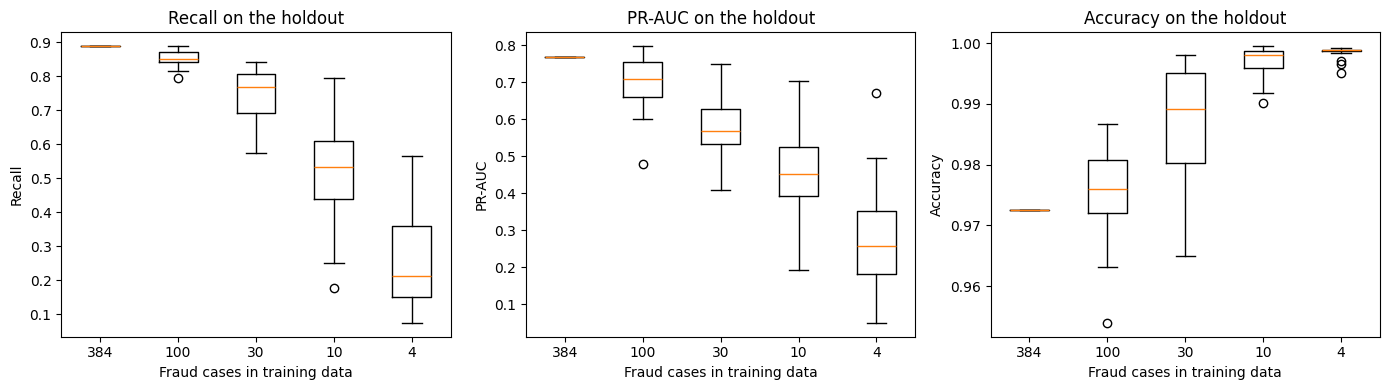

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
import matplotlib.pyplot as plt
from google.colab import files

SIZES = [None, 100, 30, 10, 4]
REPS = 30
rows = []
for size in SIZES:
    n_reps = 1 if size is None else REPS
    for rep in range(n_reps):
        fr = train_fraud if size is None else train_fraud.sample(n=size, random_state=1000 + rep)
        tr = pd.concat([train_legit, fr])
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
        model.fit(tr[features], tr["Class"])
        proba = model.predict_proba(X_test)[:, 1]
        pred = (proba >= 0.5).astype(int)
        rows.append({"n_fraud_train": len(fr), "rep": rep,
                     "recall": recall_score(y_test, pred),
                     "precision": precision_score(y_test, pred, zero_division=0),
                     "pr_auc": average_precision_score(y_test, proba),
                     "accuracy": accuracy_score(y_test, pred),
                     "n_flagged": int(pred.sum())})
    print("done:", size)

res = pd.DataFrame(rows)
res.to_csv("experiment_results.csv", index=False)

summary = (res.groupby("n_fraud_train")
    .agg(runs=("rep", "count"), flagged=("n_flagged", "mean"),
         recall=("recall", "mean"), recall_sd=("recall", "std"),
         precision=("precision", "mean"), precision_sd=("precision", "std"),
         pr_auc=("pr_auc", "mean"), pr_auc_sd=("pr_auc", "std"),
         accuracy=("accuracy", "mean"), accuracy_sd=("accuracy", "std"))
    .round(3).sort_index(ascending=False))
summary.to_csv("experiment_summary.csv")
print(summary.to_string())

order = sorted(res["n_fraud_train"].unique(), reverse=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m, t in zip(axes, ["recall", "pr_auc", "accuracy"], ["Recall", "PR-AUC", "Accuracy"]):
    ax.boxplot([res.loc[res.n_fraud_train == n, m] for n in order], tick_labels=[str(n) for n in order])
    ax.set_xlabel("Fraud cases in training data"); ax.set_ylabel(t); ax.set_title(t + " on the holdout")
plt.tight_layout(); plt.savefig("figure_subsampling.png", dpi=300); plt.show()

for f in ["experiment_results.csv", "experiment_summary.csv", "figure_subsampling.png"]:
    files.download(f)

In [37]:
metrics = ["recall", "precision", "pr_auc", "accuracy"]
out = []
for n, g in res.groupby("n_fraud_train"):
    row = {"n_fraud_train": n, "runs": len(g)}
    if "n_flagged" in g.columns:
        row["flagged_mean"] = g["n_flagged"].mean()
    for m in metrics:
        row[f"{m}_mean"] = g[m].mean()
        row[f"{m}_std"] = g[m].std()
        row[f"{m}_p2.5"] = g[m].quantile(0.025)
        row[f"{m}_p97.5"] = g[m].quantile(0.975)
    out.append(row)

summary = pd.DataFrame(out).sort_values("n_fraud_train", ascending=False).round(3)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
display(summary)
summary.to_csv("experiment_summary.csv", index=False)

,n_fraud_train,runs,recall_mean,recall_std,recall_p2.5,recall_p97.5,precision_mean,precision_std,precision_p2.5,precision_p97.5,pr_auc_mean,pr_auc_std,pr_auc_p2.5,pr_auc_p97.5,accuracy_mean,accuracy_std,accuracy_p2.5,accuracy_p97.5
4,384,1,0.889,NaN,0.889,0.889,0.040,NaN,0.040,0.040,0.768,NaN,0.768,0.768,0.973,NaN,0.973,0.973
3,100,3,0.849,0.005,0.843,0.852,0.045,0.008,0.038,0.052,0.769,0.026,0.748,0.795,0.977,0.004,0.972,0.980
2,30,3,0.682,0.035,0.658,0.719,0.147,0.132,0.046,0.286,0.528,0.029,0.501,0.555,0.990,0.009,0.980,0.997
1,10,3,0.386,0.084,0.325,0.475,0.403,0.121,0.287,0.516,0.294,0.028,0.266,0.320,0.998,0.001,0.998,0.999
0,4,3,0.222,0.042,0.179,0.258,0.708,0.101,0.602,0.789,0.287,0.069,0.224,0.354,0.999,0.000,0.999,0.999


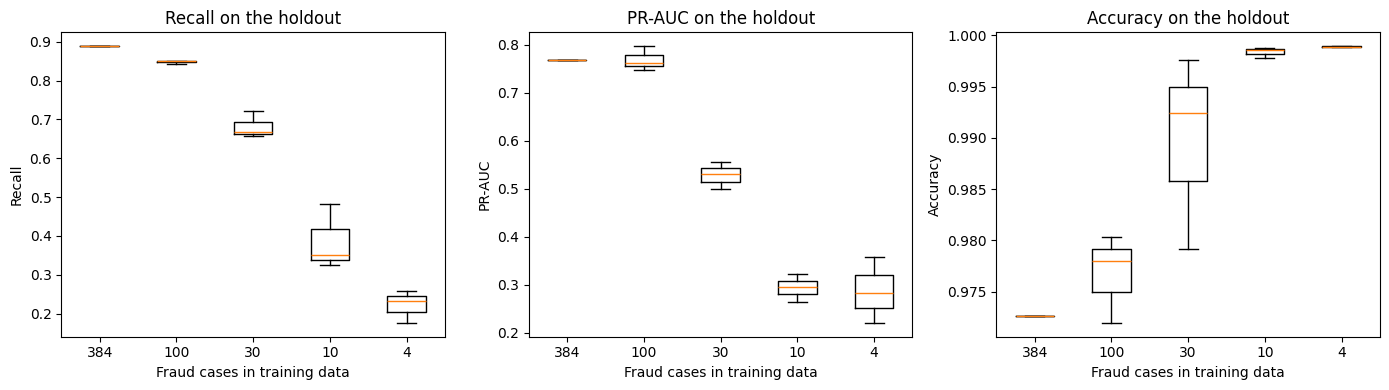

In [35]:
import matplotlib.pyplot as plt

order = sorted(res["n_fraud_train"].unique(), reverse=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m, title in zip(axes, ["recall", "pr_auc", "accuracy"],
                        ["Recall", "PR-AUC", "Accuracy"]):
    data = [res.loc[res.n_fraud_train == n, m] for n in order]
    ax.boxplot(data, tick_labels=[str(n) for n in order])
    ax.set_xlabel("Fraud cases in training data")
    ax.set_ylabel(title)
    ax.set_title(title + " on the holdout")
plt.tight_layout()
plt.savefig("figure_subsampling.png", dpi=300)
plt.show()

In [41]:
from google.colab import files
import os

for f in ["experiment_results.csv", "experiment_summary.csv", "figure_subsampling.png"]:
    if os.path.exists(f):
        files.download(f)
    else:
        print(f"Skipping {f} (file does not exist yet)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

done: None
done: 100
done: 30
done: 10
done: 4
               runs   flagged  recall  recall_sd  precision  precision_sd  pr_auc  pr_auc_sd  accuracy  accuracy_sd
n_fraud_train                                                                                                      
384               1  2424.000   0.889        NaN      0.040           NaN   0.768        NaN     0.973          NaN
100              30  2143.267   0.856      0.023      0.046         0.012   0.699      0.073     0.976        0.007
30               30  1209.933   0.750      0.073      0.111         0.083   0.578      0.081     0.986        0.010
10               30   279.833   0.524      0.144      0.337         0.206   0.453      0.124     0.997        0.003
4                30    70.533   0.250      0.130      0.572         0.247   0.270      0.136     0.999        0.001


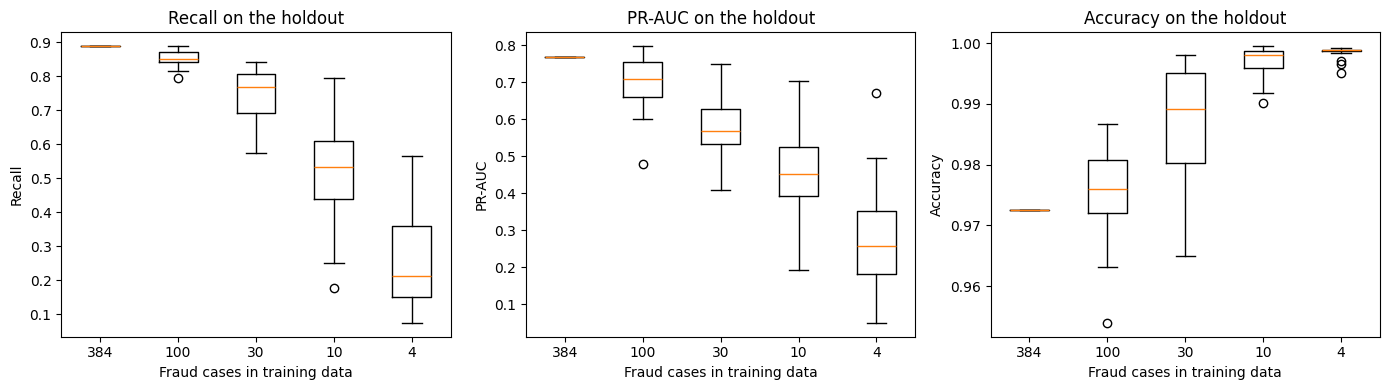

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
import matplotlib.pyplot as plt
from google.colab import files

SIZES = [None, 100, 30, 10, 4]
REPS = 30
rows = []
for size in SIZES:
    n_reps = 1 if size is None else REPS
    for rep in range(n_reps):
        fr = train_fraud if size is None else train_fraud.sample(n=size, random_state=1000 + rep)
        tr = pd.concat([train_legit, fr])
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
        model.fit(tr[features], tr["Class"])
        proba = model.predict_proba(X_test)[:, 1]
        pred = (proba >= 0.5).astype(int)
        rows.append({"n_fraud_train": len(fr), "rep": rep,
                     "recall": recall_score(y_test, pred),
                     "precision": precision_score(y_test, pred, zero_division=0),
                     "pr_auc": average_precision_score(y_test, proba),
                     "accuracy": accuracy_score(y_test, pred),
                     "n_flagged": int(pred.sum())})
    print("done:", size)

res = pd.DataFrame(rows)
res.to_csv("experiment_results.csv", index=False)

summary = (res.groupby("n_fraud_train")
    .agg(runs=("rep", "count"), flagged=("n_flagged", "mean"),
         recall=("recall", "mean"), recall_sd=("recall", "std"),
         precision=("precision", "mean"), precision_sd=("precision", "std"),
         pr_auc=("pr_auc", "mean"), pr_auc_sd=("pr_auc", "std"),
         accuracy=("accuracy", "mean"), accuracy_sd=("accuracy", "std"))
    .round(3).sort_index(ascending=False))
summary.to_csv("experiment_summary.csv")
print(summary.to_string())

order = sorted(res["n_fraud_train"].unique(), reverse=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m, t in zip(axes, ["recall", "pr_auc", "accuracy"], ["Recall", "PR-AUC", "Accuracy"]):
    ax.boxplot([res.loc[res.n_fraud_train == n, m] for n in order], tick_labels=[str(n) for n in order])
    ax.set_xlabel("Fraud cases in training data"); ax.set_ylabel(t); ax.set_title(t + " on the holdout")
plt.tight_layout(); plt.savefig("figure_subsampling.png", dpi=300); plt.show()

for f in ["experiment_results.csv", "experiment_summary.csv", "figure_subsampling.png"]:
    files.download(f)